In [1]:
import matplotlib.pyplot as plt
import numpy as np
import math

In [4]:
def memory_required(width, graph_size, LUT_SIZE):
    
    a = 2**width
    return graph_size * a + 2 * LUT_SIZE


memory_required(5, 800, 2048)

29696

# Simulation analysis

In [29]:
import os 
import pandas as pd 

MT = os.path.join("..", "python_code", "runs", "iter=1e8_PC", "LFSR_8bit_UNITS=25_N=800", "logs")


def get_data(folder):
    res = []

    for file in os.listdir(folder):
        
        full_path = os.path.join(folder, file)
        if os.path.isfile(full_path):
            
            df = pd.read_csv(full_path)
            
            res.append(np.max(df["best_maxcuts"]))
    
    return np.array(res)        


df = get_data(MT)

# sort and take 20 best solutions (however I manually checked whether the solutions actually finished : some of them were killed by the OS for some reason)
df = np.sort(df)
df = df[0:20]

avg_distance = np.mean(3050-df)
best_solution = np.max(df)
consistency = np.sum((df == best_solution))

print(f"avg_distance={avg_distance}, best_solution={best_solution}, consistency={consistency}/{len(df)}({consistency/len(df) * 100 }%)")

avg_distance=1.2, best_solution=3049.0, consistency=19/20(95.0%)


# Make plot for results

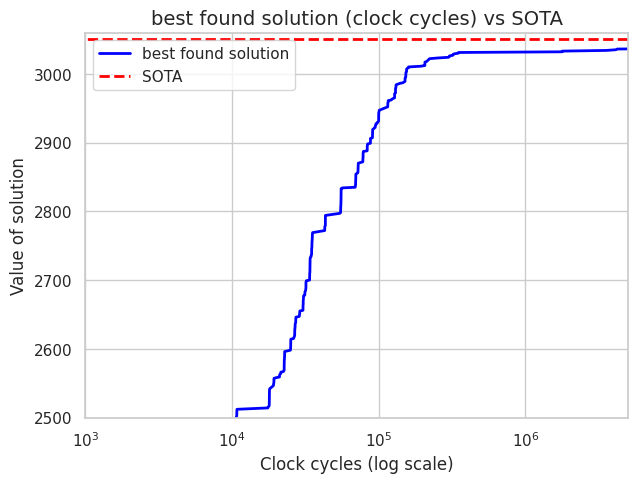

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data from the file
with open("current_best.txt") as f:
    lines = f.readlines()
    lines = [line.strip() for line in lines]
    lines = [line for line in lines if len(line) > 0]

    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip() )] for line in lines]

el = np.array(kv)

# Initialize a seaborn theme for better aesthetics
sns.set(style="whitegrid")

# Create a figure and axis
plt.figure(figsize=(7, 5))

# Plot the data
plt.plot(el[:,0], el[:,1], label="best found solution", color='blue', linewidth=2)

# Plot the SOTA line
plt.plot([min(el[:,0]), max(el[:,0])], [3050, 3050], label="SOTA", linestyle='--', color='red', linewidth=2)

# Zoom in on the region of interest and set log scale on x-axis
plt.xlim(1e3, 5e6)
plt.xscale("log")
plt.ylim(2500, 3060)

# Add labels and title
plt.xlabel("Clock cycles (log scale)", fontsize=12)
plt.ylabel("Value of solution", fontsize=12)
plt.title("best found solution (clock cycles) vs SOTA", fontsize=14)

# Add a legend
plt.legend()

# Display the plot
plt.show()

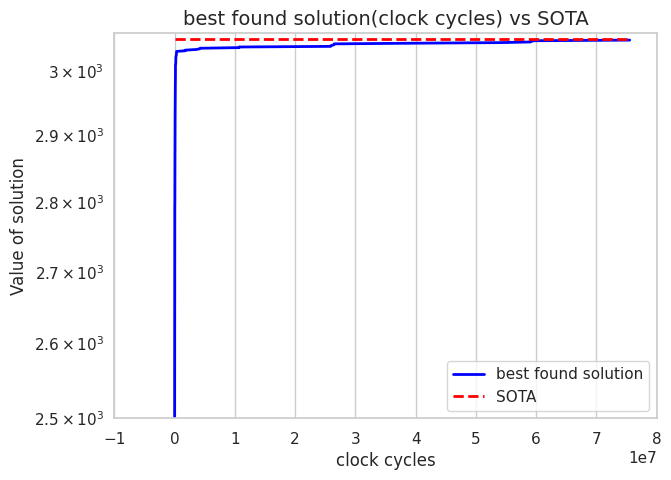

In [9]:
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data from the file
with open("current_best.txt") as f:
    lines = f.readlines()
    lines = [line.strip() for line in lines]
    lines = [line for line in lines if len(line) > 0]

    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip() )] for line in lines]

el = np.array(kv)

# Initialize a seaborn theme for better aesthetics
sns.set(style="whitegrid")

# Create a figure and axis
plt.figure(figsize=(7, 5))

# Plot the data
plt.plot(el[:,0], el[:,1], label="best found solution", color='blue', linewidth=2)

# Plot the SOTA line
plt.plot([min(el[:,0]), max(el[:,0])], [3050, 3050], label="SOTA", linestyle='--', color='red', linewidth=2)

# Zoom in on the region of interest
plt.ylim(2500, 3060)
plt.yscale("log")

# Add labels and title
plt.xlabel("clock cycles", fontsize=12)
plt.ylabel("Value of solution", fontsize=12)
plt.title("best found solution(clock cycles) vs SOTA", fontsize=14)

# Get the current x-ticks
xticks = plt.gca().get_xticks()

# Set the new x-ticks with the last step included
plt.xticks(xticks)

# Add a legend
plt.legend()

plt.savefig("current_best.png")

# Display the plot
plt.show()

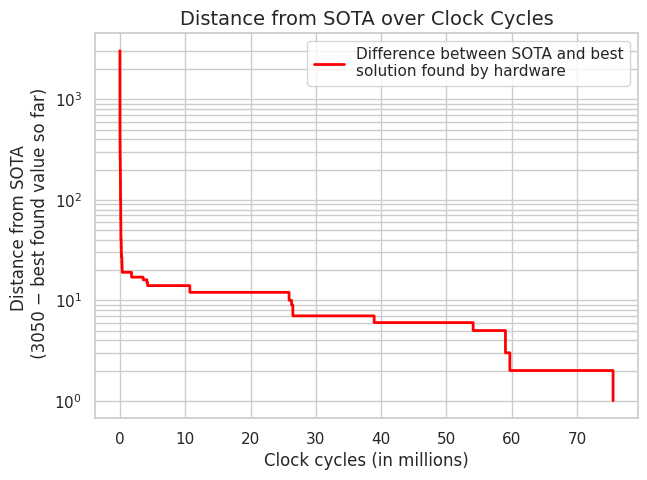

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================================
# Step 1: Load and parse the data from the file "current_best.txt"
# ----------------------------------------------------------------------------
# Each line in the file is expected to have two comma-separated values.
# We read the file, remove any empty lines, and convert the values to integers.
data_list = []  # To store our parsed data
with open("current_best.txt", "r") as file:
    for line in file:
        line = line.strip()            # Remove whitespace/newline characters
        if line:                       # Ensure the line is not empty
            # Split the line into parts, strip any extra spaces, and convert to int
            parts = line.split(",")
            clock_cycles = int(parts[0].strip())
            best_value = int(parts[1].strip())
            data_list.append([clock_cycles, best_value])
            
# Convert the list to a NumPy array for easier slicing/manipulation.
data = np.array(data_list)

# ============================================================================
# Step 2: Set the Seaborn theme for aesthetics
# ----------------------------------------------------------------------------
sns.set(style="whitegrid")

# ============================================================================
# Step 3: Compute the gap between SOTA and the best found solution so far
# ----------------------------------------------------------------------------
sota_value = 3050
# Assuming that the second column holds the "best found value so far"
gap = sota_value - data[:, 1]

# ============================================================================
# Step 4: Create the plot (using a step plot style)
# ----------------------------------------------------------------------------
plt.figure(figsize=(7, 5))

# Convert clock cycles to millions (first column) and plot the gap
# Using plt.step to create a discrete step plot.
plt.step(data[:, 0] / 1e6, gap,
         label="Difference between SOTA and best\nsolution found by hardware",
         color='red', linewidth=2, where='post')

# ============================================================================
# Step 5: Customize the plot with labels, a logarithmic y-scale, and custom y-ticks
# ----------------------------------------------------------------------------
plt.xlabel("Clock cycles (in millions)", fontsize=12)
plt.ylabel("Distance from SOTA \n (3050 − best found value so far)", fontsize=12)
plt.yscale("log")  # Use logarithmic scale for the y-axis

# Define custom ticks for the y-axis
custom_ticks = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                20, 30, 40, 50, 60, 70, 80, 90, 100,
                200, 300, 400, 500, 600, 700, 800, 900,
                1000, 2000, 3000]
plt.yticks(custom_ticks)

plt.title("Distance from SOTA over Clock Cycles", fontsize=14)
plt.legend()

# ============================================================================
# Step 6: Save the plot and display it
# ----------------------------------------------------------------------------
plt.savefig("GAP-to-SOTA_steps.png")
plt.show()


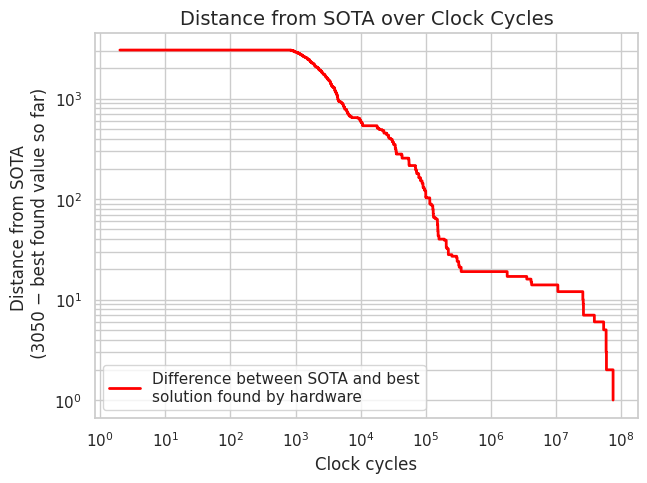

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================================
# Step 1: Load and parse the data from the file "current_best.txt"
# ----------------------------------------------------------------------------
# Each line in the file is expected to have two comma-separated values.
# We read the file, remove any empty lines, and convert the values to integers.
data_list = []  # To store our parsed data
with open("current_best.txt", "r") as file:
    for line in file:
        line = line.strip()            # Remove whitespace/newline characters
        if line:                       # Ensure the line is not empty
            # Split the line into parts, strip any extra spaces, and convert to int
            parts = line.split(",")
            clock_cycles = int(parts[0].strip())
            best_value = int(parts[1].strip())
            data_list.append([clock_cycles, best_value])
            
# Convert the list to a NumPy array for easier slicing/manipulation.
data = np.array(data_list)

# ============================================================================
# Step 2: Set the Seaborn theme for aesthetics
# ----------------------------------------------------------------------------
sns.set(style="whitegrid")

# ============================================================================
# Step 3: Compute the gap between SOTA and the best found solution so far
# ----------------------------------------------------------------------------
sota_value = 3050
# Assuming that the second column holds the "best found value so far"
gap = sota_value - data[:, 1]

# ============================================================================
# Step 4: Create the plot (using a step plot style)
# ----------------------------------------------------------------------------
plt.figure(figsize=(7, 5))

# Convert clock cycles to millions (first column) and plot the gap
# Using plt.step to create a discrete step plot.
plt.step(data[:, 0], gap,
         label="Difference between SOTA and best\nsolution found by hardware",
         color='red', linewidth=2, where='post')

# ============================================================================
# Step 5: Customize the plot with labels, a logarithmic y-scale, and custom y-ticks
# ----------------------------------------------------------------------------
plt.xlabel("Clock cycles", fontsize=12)
plt.ylabel("Distance from SOTA \n (3050 − best found value so far)", fontsize=12)
plt.yscale("log")  # Use logarithmic scale for the y-axis
plt.xscale("log")

# Define custom ticks for the y-axis
custom_ticks = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                20, 30, 40, 50, 60, 70, 80, 90, 100,
                200, 300, 400, 500, 600, 700, 800, 900,
                1000, 2000, 3000]
plt.yticks(custom_ticks)

plt.title("Distance from SOTA over Clock Cycles", fontsize=14)
plt.legend()

# ============================================================================
# Step 6: Save the plot and display it
# ----------------------------------------------------------------------------
plt.savefig("GAP-to-SOTA_steps_xscale_log.png")
plt.show()

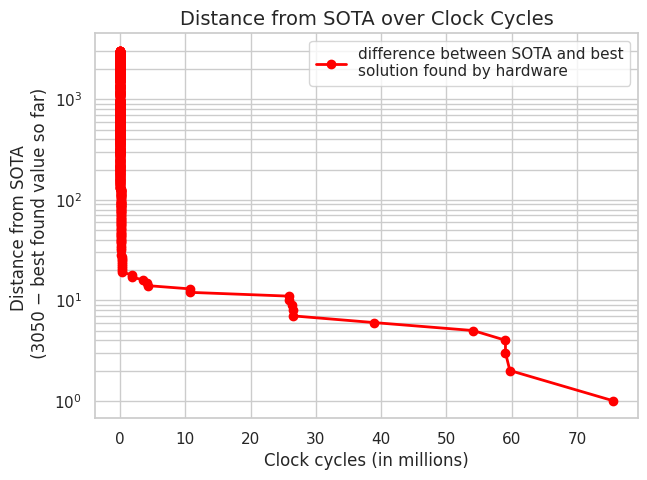

In [35]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data from the file
with open("current_best.txt") as f:
    lines = f.readlines()
    lines = [line.strip() for line in lines]
    lines = [line for line in lines if len(line) > 0]
    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip())] for line in lines]

el = np.array(kv)

# Set a seaborn theme for aesthetics
sns.set(style="whitegrid")

# Compute the gap between SOTA and best found solution
sota_value = 3050
gap = sota_value - el[:, 1]

plt.figure(figsize=(7, 5))
# Convert clock cycles to millions and plot the gap with markers
plt.plot(el[:, 0] / 1e6, gap, 
         label="difference between SOTA and best\nsolution found by hardware",
         color='red', linewidth=2, marker='o', markersize=6)

plt.xlabel("Clock cycles (in millions)", fontsize=12)
plt.ylabel("Distance from SOTA \n (3050 \u2212 best found value so far)", fontsize=12)
plt.yscale("log")

# Set custom y-axis ticks
custom_ticks = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 
                200, 300, 400, 500, 600, 700, 800, 900, 1000, 2000, 3000]
plt.yticks(custom_ticks)

plt.title("Distance from SOTA over Clock Cycles", fontsize=14)
plt.legend()
plt.savefig("GAP-to-SOTA.png")
plt.show()


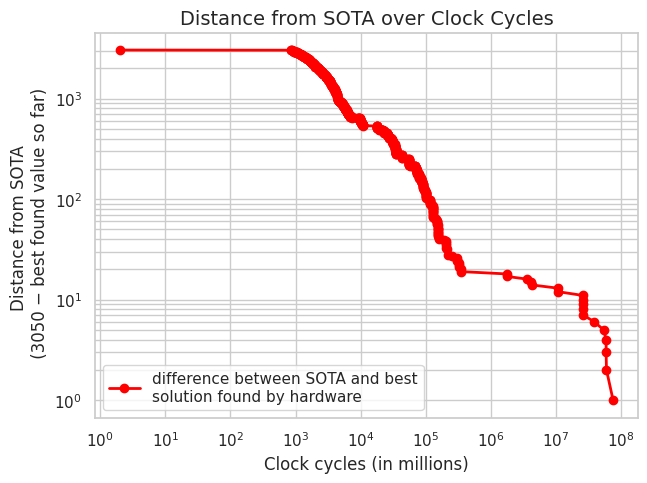

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data from the file
with open("current_best.txt") as f:
    lines = f.readlines()
    lines = [line.strip() for line in lines]
    lines = [line for line in lines if len(line) > 0]
    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip())] for line in lines]

el = np.array(kv)

# Set a seaborn theme for aesthetics
sns.set(style="whitegrid")

# Compute the gap between SOTA and best found solution
sota_value = 3050
gap = sota_value - el[:, 1]

plt.figure(figsize=(7, 5))
# Convert clock cycles to millions and plot the gap with markers
plt.plot(el[:, 0], gap, 
         label="difference between SOTA and best\nsolution found by hardware",
         color='red', linewidth=2, marker='o', markersize=6)

plt.xlabel("Clock cycles (in millions)", fontsize=12)
plt.ylabel("Distance from SOTA \n (3050 \u2212 best found value so far)", fontsize=12)
plt.yscale("log")
plt.xscale("log")

# Set custom y-axis ticks
custom_ticks = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 
                200, 300, 400, 500, 600, 700, 800, 900, 1000, 2000, 3000]
plt.yticks(custom_ticks)

plt.title("Distance from SOTA over Clock Cycles", fontsize=14)
plt.legend()
plt.savefig("GAP-to-SOTA_markers.png")
plt.show()


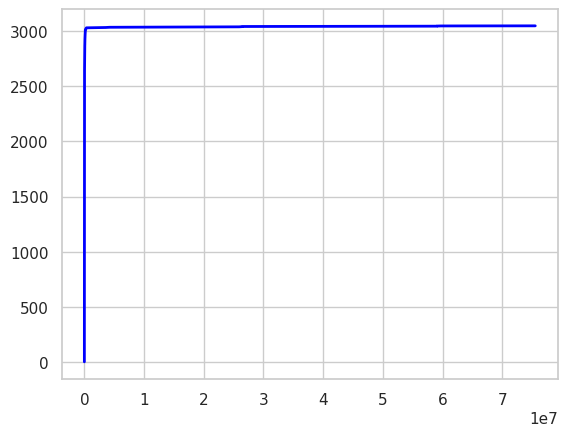

In [5]:
plt.plot(el[:,0], el[:,1], label="best found solution", color='blue', linewidth=2)

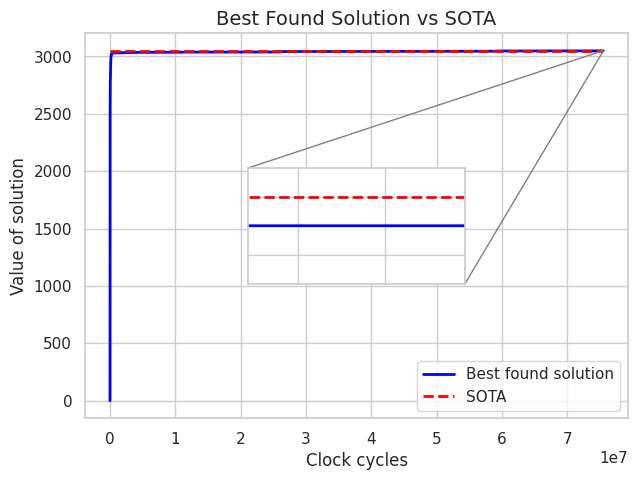

In [17]:
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Load your data (same as your code)
with open("current_best.txt") as f:
    lines = [line.strip() for line in f if line.strip()]
    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip())] for line in lines]
el = np.array(kv)

sns.set(style="whitegrid")
fig, ax = plt.subplots(figsize=(7, 5))

# Plot the best found solution and SOTA line
ax.plot(el[:, 0], el[:, 1], label="Best found solution", color='blue', linewidth=2)
ax.plot([min(el[:, 0]), max(el[:, 0])], [3050, 3050], label="SOTA", linestyle='--', color='red', linewidth=2)
ax.set_xlabel("Clock cycles", fontsize=12)
ax.set_ylabel("Value of solution", fontsize=12)
ax.set_title("Best Found Solution vs SOTA", fontsize=14)
ax.legend()

# Create an inset axis to zoom in on the convergence region
axins = inset_axes(ax, width="40%", height="30%", loc='center')
axins.plot(el[:, 0], el[:, 1], color='blue', linewidth=2)
axins.plot([min(el[:, 0]), max(el[:, 0])], [3050, 3050], linestyle='--', color='red', linewidth=2)

# Choose a zoom region (adjust these values as needed)
# For example, zoom in on the last 500 clock cycles and the y-range [3047, 3051]
x1 = el[-1, 0] - 500  
x2 = el[-1, 0]
y1, y2 = 3047, 3051
axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)

# Hide tick labels on the inset for clarity
axins.set_xticklabels([])
axins.set_yticklabels([])
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5")

plt.show()


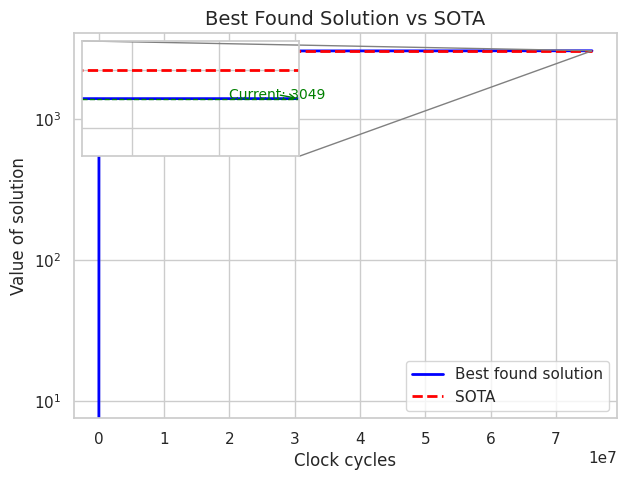

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Load the data from the file
with open("current_best.txt") as f:
    # Read and filter out empty lines
    lines = [line.strip() for line in f if line.strip()]
    # Parse each line as two integers (clock cycle, solution value)
    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip())] for line in lines]

# Convert the data to a numpy array
el = np.array(kv)

# Set a seaborn theme for aesthetics
sns.set(style="whitegrid")

# Create the main figure and axis
fig, ax = plt.subplots(figsize=(7, 5))

# Plot the best found solution and the SOTA line
ax.plot(el[:, 0], el[:, 1], label="Best found solution", color='blue', linewidth=2)
ax.plot([el[:, 0].min(), el[:, 0].max()], [3050, 3050],
        label="SOTA", linestyle='--', color='red', linewidth=2)

# Label the axes and add a title
ax.set_xlabel("Clock cycles", fontsize=12)
ax.set_ylabel("Value of solution", fontsize=12)
ax.set_title("Best Found Solution vs SOTA", fontsize=14)
ax.legend()

ax.set_yscale("log")

# --- Inset: Zooming in on the convergence region ---
# Create an inset axis within the main axis.
axins = inset_axes(ax, width="40%", height="30%", loc='upper left')

# Plot the same data on the inset axis.
axins.plot(el[:, 0], el[:, 1], color='blue', linewidth=2)
axins.plot([el[:, 0].min(), el[:, 0].max()], [3050, 3050],
           linestyle='--', color='red', linewidth=2)

# Define the zoom region.
# For example, we zoom in on the last 500 clock cycles and y-range from 3047 to 3051.
x1 = el[-1, 0] - 500  
x2 = el[-1, 0]
y1, y2 = 3047, 3051
axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)

# Hide tick labels on the inset for clarity.
axins.set_xticklabels([])
axins.set_yticklabels([])

# Annotate the current solution value in the inset.
current_value = el[-1, 1]  # Last value in your dataset (e.g., 3049)
axins.axhline(current_value, color='green', linestyle='--', linewidth=1)
axins.annotate(f"Current: {current_value}",
               xy=(x2, current_value),
               xytext=(-50, 0),  # offset in points
               textcoords='offset points',
               arrowprops=dict(arrowstyle="->", color='green'),
               color='green',
               fontsize=10)

# Draw a box around the inset region on the main plot.
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5")

plt.show()


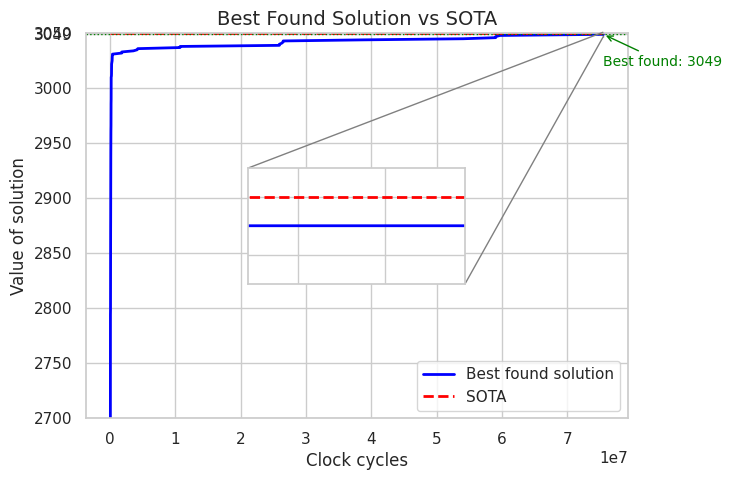

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Load the data from the file
with open("current_best.txt") as f:
    lines = [line.strip() for line in f if line.strip()]
    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip())] for line in lines]

# Convert the data to a numpy array
el = np.array(kv)

# Set a seaborn theme for aesthetics
sns.set(style="whitegrid")

# Create the main figure and axis
fig, ax = plt.subplots(figsize=(7, 5))

# Plot the best found solution and the SOTA line on the main axis
ax.plot(el[:, 0], el[:, 1], label="Best found solution", color='blue', linewidth=2)
ax.plot([el[:, 0].min(), el[:, 0].max()], [3050, 3050],
        label="SOTA", linestyle='--', color='red', linewidth=2)

# Label axes and add title
ax.set_xlabel("Clock cycles", fontsize=12)
ax.set_ylabel("Value of solution", fontsize=12)
ax.set_title("Best Found Solution vs SOTA", fontsize=14)

# Crop the main y-axis to focus on the region of interest
ax.set_ylim(2700, 3050)

# Ensure the best found value (3049) appears as a tick on the y-axis.
yticks = list(ax.get_yticks())
if 3049 not in yticks:
    yticks.append(3049)
    yticks = sorted(yticks)
ax.set_yticks(yticks)

# Mark the best found solution (3049) on the main plot with a horizontal line and annotation.
ax.axhline(3049, color='green', linestyle=':', linewidth=1)
ax.annotate("Best found: 3049",
            xy=(el[-1, 0], 3049),
            xytext=(el[-1, 0] - 100, 3020),
            arrowprops=dict(arrowstyle="->", color='green'),
            color='green',
            fontsize=10)

ax.legend()

# --- Inset: Zooming in on the convergence region ---
# Place the inset in the middle of the main axis.
axins = inset_axes(ax, width="40%", height="30%", loc='center')

# Plot the same data on the inset axis.
axins.plot(el[:, 0], el[:, 1], color='blue', linewidth=2)
axins.plot([el[:, 0].min(), el[:, 0].max()], [3050, 3050],
           linestyle='--', color='red', linewidth=2)

# Define the zoom region.
# For example, we zoom in on the last 500 clock cycles and a y-range around the best found solution.
x1 = el[-1, 0] - 500  
x2 = el[-1, 0]
y1, y2 = 3047, 3051
axins.set_xlim(x1, x2)
axins.set_ylim(y1, y2)

# Hide tick labels on the inset for clarity.
axins.set_xticklabels([])
axins.set_yticklabels([])

# Draw a box on the main plot that shows the zoomed area.
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5")

plt.show()


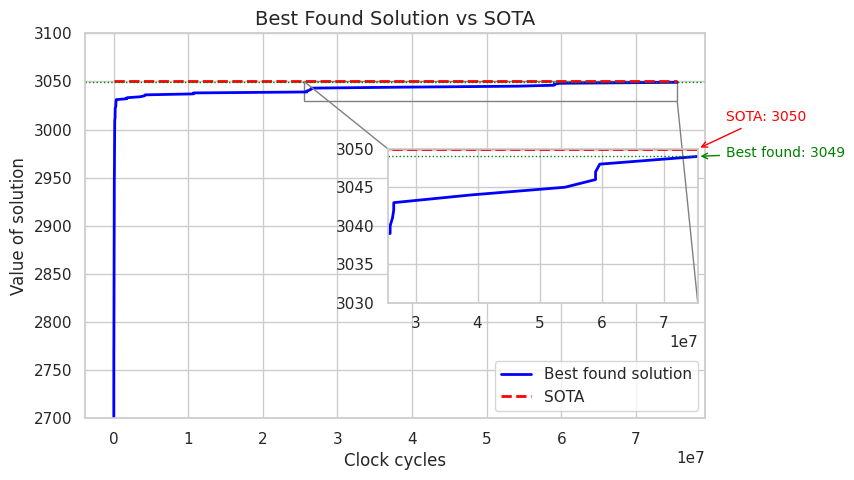

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# Load the data from the file
with open("current_best.txt") as f:
    lines = [line.strip() for line in f if line.strip()]
    kv = [[int(line.split(",")[0].strip()), int(line.split(",")[1].strip())] for line in lines]

# Convert the data to a numpy array
el = np.array(kv)

# Set a seaborn theme for aesthetics
sns.set(style="whitegrid")

# Create the main figure and axis
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the best found solution and the SOTA line on the main axis
ax.plot(el[:, 0], el[:, 1], label="Best found solution", color='blue', linewidth=2)
ax.plot([el[:, 0].min(), el[:, 0].max()], [3050, 3050],
        label="SOTA", linestyle='--', color='red', linewidth=2)

# Label axes and add title
ax.set_xlabel("Clock cycles", fontsize=12)
ax.set_ylabel("Value of solution", fontsize=12)
ax.set_title("Best Found Solution vs SOTA", fontsize=14)

# Crop the main y-axis to focus on the region of interest
ax.set_ylim(2700, 3055)

# Ensure the best found value (3049) appears as a tick on the y-axis.
yticks = list(ax.get_yticks())
ax.set_yticks(yticks)

# Mark the best found solution (3049) on the main plot with a horizontal line and annotation.
ax.axhline(3049, color='green', linestyle=':', linewidth=1)
ax.legend()

# --- Inset: Zooming in on a longer period in the convergence region ---
# Place the inset in the middle of the main axis.
axins = inset_axes(ax, width="50%", height="40%", loc='center right')

# Plot the same data on the inset axis.
axins.plot(el[:, 0], el[:, 1], color='blue', linewidth=2)
axins.plot([el[:, 0].min(), el[:, 0].max()], [3050, 3050],
           linestyle='--', color='red', linewidth=2)

# Define the zoom region:
#   x-range: a longer period (e.g. last 1000 clock cycles)
#   y-range: zoom on values from 3030 to 3050 (this includes the best found value 3049 and SOTA at 3050)
x1 = el[-1, 0] - 50_000_000  # Adjust if your dataset is shorter than 1000 cycles
x2 = el[-1, 0]
axins.set_xlim(x1, x2)
axins.set_ylim(3030, 3050)

# Annotate the best found solution (3049) in the inset.
axins.axhline(3049, color='green', linestyle=':', linewidth=1)
axins.annotate("Best found: 3049", 
               xy=(el[-1, 0], 3049), 
               xytext=(20, 00),  # offset in points relative to the annotated point
               textcoords="offset points",
               arrowprops=dict(arrowstyle="->", color='green'),
               color='green',
               fontsize=10)

# Annotate SOTA (3050) in the inset.
axins.axhline(3050, color='red', linestyle='--', linewidth=1)
axins.annotate("SOTA: 3050",
               xy=(x2, 3050),
               xytext=(20, 20),
               textcoords="offset points",
               arrowprops=dict(arrowstyle="->", color='red'),
               color='red',
               fontsize=10)

# Hide tick labels on the inset for clarity.
#axins.set_xticklabels([])
#saxins.set_yticklabels([])

# Draw a box on the main plot that indicates the zoomed region.
mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5")

plt.show()
